# Implement an ensemble learning method (e.g., Random Forest or Gradient Boosting) to classify cyber-attacks. 

In [31]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [32]:
df = pd.read_csv("Attack_Dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (14133, 16)
   ID                                    Title                  Category  \
0   1  Authentication Bypass via SQL Injection           Mobile Security   
1   2                Union-Based SQL Injection  AI Agents & LLM Exploits   
2   3                Error-Based SQL Injection  AI Agents & LLM Exploits   
3   4                      Blind SQL Injection  AI Agents & LLM Exploits   
4   5               Second-Order SQL Injection  AI Agents & LLM Exploits   

            Attack Type                               Scenario Description  \
0  SQL Injection (SQLi)  A login form fails to validate or sanitize inp...   
1         SQL Injection  This attack occurs when a hacker uses the SQL ...   
2         SQL Injection  This attack occurs when an attacker intentiona...   
3         SQL Injection  In Blind SQL Injection, the attacker doesn’t s...   
4         SQL Injection  In a Second-Order SQL Injection, the attacker ...   

                                          Tools

In [33]:
print("Unique categories:", df["Category"].nunique())

print("\nCategory distribution:")
print(df["Category"].value_counts())

Unique categories: 64

Category distribution:
Category
Insider Threat                                                   569
Physical / Hardware Attacks                                      548
Quantum Cryptography & Post-Quantum Threats                      542
Wireless Attacks (Advanced)                                      535
Malware & Threat                                                 528
                                                                ... 
Automotive / Cyber-Physical Systems → ECU Reverse Engineering      7
Automotive / CPS → Firmware Over-The-Air (FOTA) Abuse              5
Automotive / CPS → Physical Layer Attack                           3
Network security                                                   2
 Mobile Security                                                   1
Name: count, Length: 64, dtype: int64


In [34]:
counts = df["Category"].value_counts()

rare = counts[counts < 10].index

df["Category"] = df["Category"].replace(rare, "Other")

print("Categories after grouping:", df["Category"].nunique())

print("\nUpdated distribution:")
print(df["Category"].value_counts())

Categories after grouping: 59

Updated distribution:
Category
Insider Threat                                                                                                 569
Physical / Hardware Attacks                                                                                    548
Quantum Cryptography & Post-Quantum Threats                                                                    542
Wireless Attacks (Advanced)                                                                                    535
Malware & Threat                                                                                               528
Satellite & Space Infrastructure Security                                                                      515
DFIR                                                                                                           510
Blockchain / Web3                                                                                              503
Blue Team         

In [35]:
X = df[[
    "Target Type",
    "MITRE Technique"
]].fillna("Unknown")

y = df["Category"].fillna("Unknown")

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['Target Type', 'MITRE Technique']
Target: Category


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 11306
Testing samples: 2827


In [37]:
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), X.columns)
])

In [38]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [39]:
y_pred = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [40]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", round(accuracy * 100, 2))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Accuracy: 0.40148567385921474
Accuracy (%): 40.15

Classification Report:
                                                                                                             precision    recall  f1-score   support

                                                                                   AI Agents & LLM Exploits       0.52      0.15      0.23        99
                                                                            AI Data Leakage & Privacy Risks       0.61      0.19      0.29       100
                                                                                             AI/ML Security       0.88      0.30      0.45        99
                                                                                           Automotive / CPS       0.00      0.00      0.00         2
                                                Automotive / CPS → Sensor Spoofing & Physical Layer Attacks       1.00      0.50      0.67         2
                               

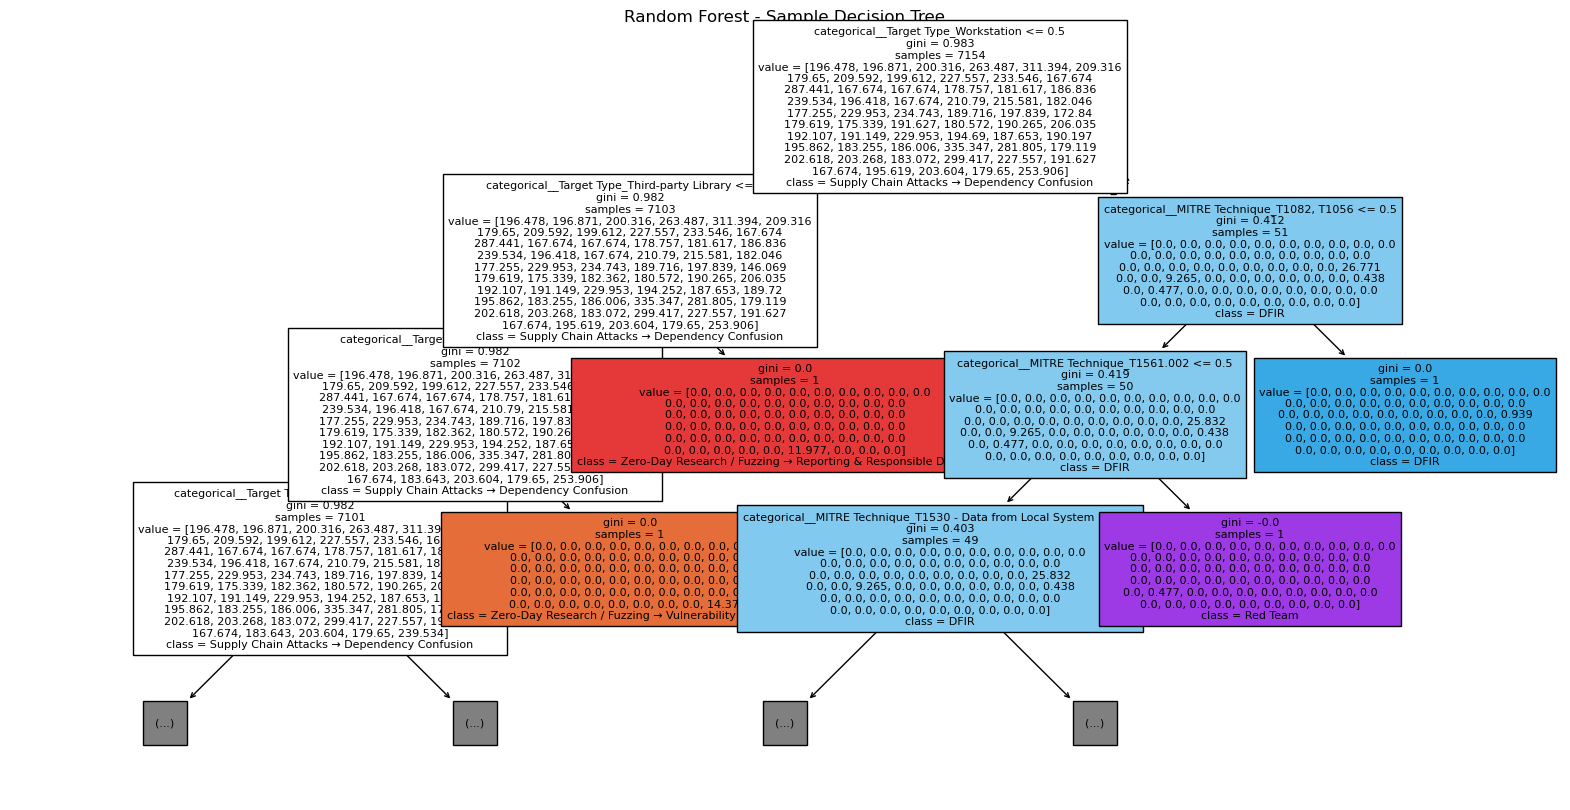

In [41]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

rf = model.named_steps["classifier"]
preprocessor = model.named_steps["preprocessor"]

X_train_encoded = preprocessor.transform(X_train)
feature_names = preprocessor.get_feature_names_out()

plt.figure(figsize=(20, 10))

plot_tree(
    rf.estimators_[0],
    feature_names=feature_names,
    class_names=rf.classes_,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Random Forest - Sample Decision Tree")
plt.show()